In [2]:
import mne
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mne.time_frequency import psd_array_multitaper

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE

%matplotlib inline

In [6]:
# путь к одному файлу для примера
path = "/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС010_19/T-1.edf"
path_pok = "/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС010_19/T-П.edf"

raw = mne.io.read_raw_edf(path, preload=True)
raw_p = mne.io.read_raw_edf(path_pok, preload=True)

print(raw.ch_names)        # список каналов
print(raw.info["sfreq"])   # частота дискретизации
print(raw.n_times)         # число отсчётов
print(raw.n_times / raw.info["sfreq"], "секунд")

data = raw.get_data()      # numpy-массив [n_channels, n_samples], в вольтах
print(data.shape)

Extracting EDF parameters from /home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС010_19/T-1.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7874  =      0.000 ...    62.992 secs...
Extracting EDF parameters from /home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС010_19/T-П.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7874  =      0.000 ...    62.992 secs...
['O1', 'T3', 'Fp1', 'Fp2', 'T4', 'O2']
125.0
7875
63.0 секунд
(6, 7875)


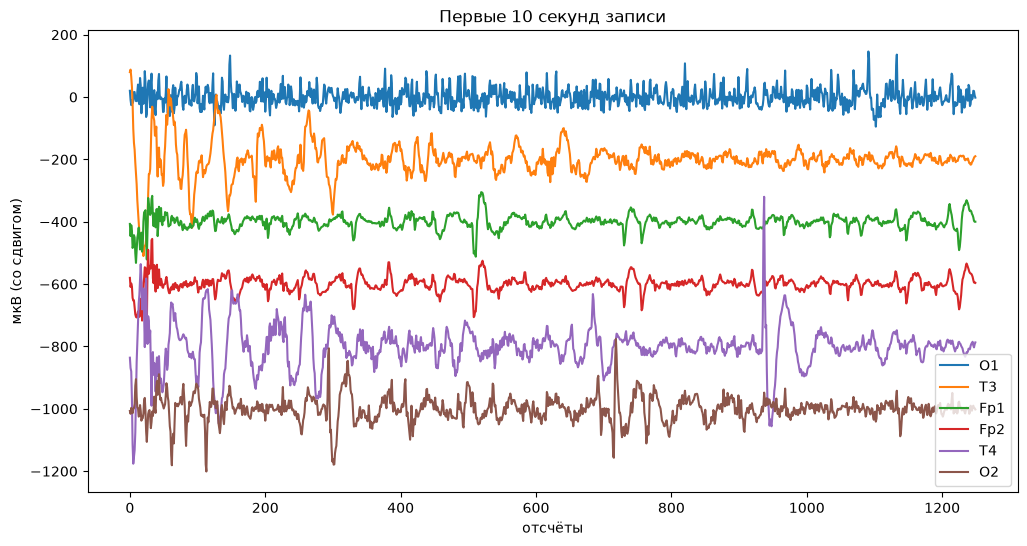

In [7]:
import matplotlib.pyplot as plt
CHANNELS = raw.ch_names
data = raw.get_data() * 1e6   # mne хранит в вольтах, переводим в микровольты
fs = raw.info["sfreq"]

secs = 10                      # первые 10 секунд
n = int(secs * fs)

plt.figure(figsize=(12, 6))
for i, ch in enumerate(CHANNELS):
    plt.plot(data[i, :n] - i * 200, label=ch)   # сдвигаем каналы по вертикали, чтоб не накладывались
plt.legend()
plt.xlabel("отсчёты")
plt.ylabel("мкВ (со сдвигом)")
plt.title("Первые 10 секунд записи")
plt.show()


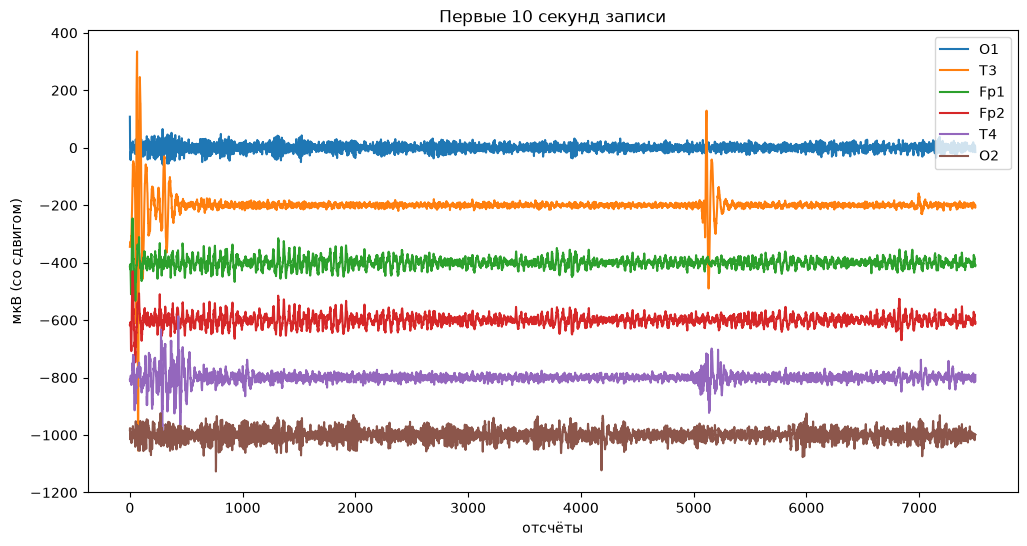

In [8]:
CHANNELS = raw_p.ch_names
data = raw_p.get_data() * 1e6   # mne хранит в вольтах, переводим в микровольты
fs = raw_p.info["sfreq"]

secs = 60                      # первые 10 секунд
n = int(secs * fs)

plt.figure(figsize=(12, 6))
for i, ch in enumerate(CHANNELS):
    plt.plot(data[i, :n] - i * 200, label=ch)   # сдвигаем каналы по вертикали, чтоб не накладывались
plt.legend()
plt.xlabel("отсчёты")
plt.ylabel("мкВ (со сдвигом)")
plt.title("Первые 10 секунд записи")
plt.show()


In [10]:
from pathlib import Path
import re

DATA_DIR = Path("/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train")   # подставьте свой путь

for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subjects = [d for d in group_dir.iterdir() if d.is_dir()]
    print(f"{group_dir.name}: {len(subjects)} испытуемых")


Норма: 67 испытуемых
ПТСР: 25 испытуемых
Соматоформные: 74 испытуемых


In [11]:
def classify_file(stem: str):
    """Определяем тип файла по имени: покой (суффикс _П/_p/rest) или таблица (суффикс _1.._5)."""
    if re.search(r"(?:^|[_\-\s])(п|p|rest|покой)$", stem, re.I):
        return "rest"
    m = re.search(r"(?:^|[_\-\s])(\d+)$", stem)
    if m:
        return f"task_{m.group(1)}"
    return "unknown"

problems = []

for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        edfs = sorted(subj_dir.glob("*.edf"))
        kinds = [classify_file(f.stem) for f in edfs]

        n_rest = kinds.count("rest")
        n_task = sum(k.startswith("task_") for k in kinds)
        n_unknown = kinds.count("unknown")

        # возраст (актуально только для группы "Норма")
        age_match = re.search(r"_(\d+)$", subj_dir.name)
        age = age_match.group(1) if age_match else None

        if n_rest != 1 or n_task != 5 or n_unknown > 0:
            problems.append((group_dir.name, subj_dir.name, len(edfs), n_rest, n_task, n_unknown, [f.name for f in edfs]))

        if group_dir.name.lower().startswith("норм") and age is None:
            print(f"[!] нет возраста в имени папки: {subj_dir.name}")

print(f"\nВсего проблемных испытуемых (не 1 покой + 5 таблиц): {len(problems)}")
for p in problems[:20]:
    print(p)



Всего проблемных испытуемых (не 1 покой + 5 таблиц): 0


In [12]:
import mne
import numpy as np
import pandas as pd
from pathlib import Path

mne.set_log_level("ERROR")  # чтобы не заваливало вывод служебными сообщениями
CHANNELS = ["Fp1", "Fp2", "T3", "T4", "O1", "O2"]

def classify_file(stem: str):
    if re.search(r"(?:^|[_\-\s])(п|p|rest|покой)$", stem, re.I):
        return "rest"
    m = re.search(r"(?:^|[_\-\s])(\d+)$", stem)
    return f"task_{m.group(1)}" if m else "unknown"

rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        for f in sorted(subj_dir.glob("*.edf")):
            kind = classify_file(f.stem)
            row = dict(group=group_dir.name, subject=subj_dir.name, file=f.name, kind=kind)
            try:
                raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
                raw.pick(CHANNELS)
                data = raw.get_data() * 1e6  # микровольты

                row["fs"] = raw.info["sfreq"]
                row["duration_s"] = raw.n_times / raw.info["sfreq"]
                row["amp_p99_uV"] = float(np.percentile(np.abs(data), 99))  # грубая оценка масштаба

                if kind == "rest":
                    # альфа-пик на затылочных каналах O1/O2
                    psd = raw.compute_psd(method="welch", fmin=1, fmax=30, picks=["O1", "O2"], verbose=False)
                    freqs = psd.freqs
                    p = psd.get_data().mean(axis=0)  # усредняем O1 и O2
                    alpha_mask = (freqs >= 7) & (freqs <= 13)
                    row["alpha_peak_hz"] = float(freqs[alpha_mask][p[alpha_mask].argmax()])
                    # есть ли реально выраженный пик (мощность в альфе заметно выше соседей)?
                    row["alpha_prominent"] = bool(p[alpha_mask].max() > 1.5 * np.median(p))

            except Exception as e:
                row["error"] = str(e)
            rows.append(row)

df = pd.DataFrame(rows)

print("Файлов не прочиталось:", df["error"].notna().sum() if "error" in df else 0)
if "error" in df and df["error"].notna().any():
    print(df[df["error"].notna()][["group", "subject", "file", "error"]])

print("\n--- Частоты дискретизации ---")
print(df["fs"].value_counts())

print("\n--- Длительности по типу файла (с) ---")
print(df.groupby(df["kind"].apply(lambda k: "rest" if k == "rest" else "task"))["duration_s"].describe().round(1))

print("\n--- Масштаб амплитуды (99-й перцентиль, мкВ) ---")
print(df["amp_p99_uV"].describe().round(1))
print("По группам:")
print(df.groupby("group")["amp_p99_uV"].describe().round(1))

print("\n--- Альфа-пик в покое (O1/O2) ---")
rest = df[df["kind"] == "rest"]
print(rest["alpha_peak_hz"].describe().round(2))
print(f"Доля с выраженным пиком: {rest['alpha_prominent'].mean():.0%}")
print(rest.groupby("group")["alpha_prominent"].mean().round(2))


/tmp/ipykernel_18354/2707270209.py:26: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/2707270209.py:26: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/2707270209.py:26: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/2707270209.py:26: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  ra

Файлов не прочиталось: 5
             group subject     file                   error
930  Соматоформные   XCFU5  T-1.edf  Bad EDF file provided.
931  Соматоформные   XCFU5  T-2.edf  Bad EDF file provided.
932  Соматоформные   XCFU5  T-3.edf  Bad EDF file provided.
933  Соматоформные   XCFU5  T-4.edf  Bad EDF file provided.
934  Соматоформные   XCFU5  T-5.edf  Bad EDF file provided.

--- Частоты дискретизации ---
fs
125.0    783
126.0     58
124.0     52
127.0     51
123.0     47
Name: count, dtype: int64

--- Длительности по типу файла (с) ---
      count  mean   std   min   25%   50%   75%    max
kind                                                  
rest  166.0  62.1   9.4  32.0  61.0  61.0  62.0  121.0
task  825.0  47.5  17.0   1.0  36.0  44.0  53.0  142.0

--- Масштаб амплитуды (99-й перцентиль, мкВ) ---
count      991.0
mean       604.4
std       1556.1
min         14.6
25%         53.0
50%         84.0
75%        349.8
max      32767.0
Name: amp_p99_uV, dtype: float64
По группам:

In [13]:
# 1. Найдём конкретные файлы-выбросы, а не только средние по группе
outliers = df[df["amp_p99_uV"] > 2000].sort_values("amp_p99_uV", ascending=False)
print(outliers[["group", "subject", "file", "amp_p99_uV"]])

             group subject     file  amp_p99_uV
905  Соматоформные   VBNM0  T-П.edf    32767.00
703  Соматоформные   KREH6  T-2.edf    10282.13
575  Соматоформные   BIOM7  T-П.edf    10024.09
702  Соматоформные   KREH6  T-1.edf     8182.33
682  Соматоформные   JWKL7  T-5.edf     7564.57
..             ...     ...      ...         ...
553  Соматоформные   ABXZ5  T-2.edf     2030.01
862  Соматоформные   SIGO3  T-5.edf     2015.51
887  Соматоформные   TMVN4  T-П.edf     2015.51
886  Соматоформные   TMVN4  T-5.edf     2015.51
585  Соматоформные   BLDY8  T-4.edf     2014.12

[86 rows x 4 columns]


In [14]:
print(len(outliers["group"]))

86


In [15]:
df.head(-10)

,group,subject,file,kind,fs,duration_s,amp_p99_uV,alpha_peak_hz,alpha_prominent,error
0,Норма,КС010_19,T-1.edf,task_1,125.0,63.0,145.0,NaN,NaN,NaN
1,Норма,КС010_19,T-2.edf,task_2,125.0,44.0,81.0,NaN,NaN,NaN
2,Норма,КС010_19,T-3.edf,task_3,125.0,50.0,60.0,NaN,NaN,NaN
3,Норма,КС010_19,T-4.edf,task_4,125.0,33.0,71.0,NaN,NaN,NaN
4,Норма,КС010_19,T-5.edf,task_5,125.0,50.0,69.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
981,Соматоформные,ZJLO6,T-4.edf,task_4,125.0,33.0,60.0,NaN,NaN,NaN
982,Соматоформные,ZJLO6,T-5.edf,task_5,125.0,47.0,48.0,NaN,NaN,NaN
983,Соматоформные,ZJLO6,T-П.edf,rest,125.0,61.0,33.0,11.047363,True,NaN
984,Соматоформные,ZWAX5,T-1.edf,task_1,125.0,45.0,130.0,NaN,NaN,NaN


In [16]:
# 2. Для них проверим, есть ли "полка" на максимуме/минимуме (признак клиппинга)
def clipping_fraction(data, tol=1e-6):
    """Доля отсчётов на каждом канале, "прилипших" к макс./мин. значению этого файла."""
    hi = data.max(axis=1, keepdims=True)
    lo = data.min(axis=1, keepdims=True)
    at_edge = np.isclose(data, hi, atol=tol, rtol=0) | np.isclose(data, lo, atol=tol, rtol=0)
    return at_edge.mean(axis=1)

for _, row in outliers.head(10).iterrows():
    f = DATA_DIR / row["group"] / row["subject"] / row["file"]
    raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    cf = clipping_fraction(data)
    print( row["group"] , row["subject"],row["file"], dict(zip(CHANNELS, cf.round(4))))


Соматоформные VBNM0 T-П.edf {'Fp1': np.float64(0.0003), 'Fp2': np.float64(0.0003), 'T3': np.float64(0.0499), 'T4': np.float64(0.0133), 'O1': np.float64(0.0317), 'O2': np.float64(0.0051)}
Соматоформные KREH6 T-2.edf {'Fp1': np.float64(0.0003), 'Fp2': np.float64(0.0003), 'T3': np.float64(0.0199), 'T4': np.float64(0.0007), 'O1': np.float64(0.0007), 'O2': np.float64(0.0003)}
Соматоформные BIOM7 T-П.edf {'Fp1': np.float64(0.0003), 'Fp2': np.float64(0.0003), 'T3': np.float64(0.0003), 'T4': np.float64(0.0003), 'O1': np.float64(0.0003), 'O2': np.float64(0.0003)}
Соматоформные KREH6 T-1.edf {'Fp1': np.float64(0.0005), 'Fp2': np.float64(0.0008), 'T3': np.float64(0.0045), 'T4': np.float64(0.0018), 'O1': np.float64(0.0022), 'O2': np.float64(0.0003)}
Соматоформные JWKL7 T-5.edf {'Fp1': np.float64(0.0015), 'Fp2': np.float64(0.001), 'T3': np.float64(0.0075), 'T4': np.float64(0.0014), 'O1': np.float64(0.0003), 'O2': np.float64(0.0003)}
Соматоформные KJFS5 T-4.edf {'Fp1': np.float64(0.0006), 'Fp2': np.

In [ ]:
from scipy import signal
import numpy as np

def rel_power_by_band(data, fs, bands):
    """Возвращает {диапазон: доля мощности} усреднённо по каналам."""
    f, p = signal.welch(data, fs=fs, nperseg=int(4 * fs), axis=1)
    total = p[:, (f >= 1) & (f <= 40)].sum(axis=1, keepdims=True)
    out = {}
    for name, (lo, hi) in bands.items():
        mask = (f >= lo) & (f < hi)
        out[name] = (p[:, mask].sum(axis=1) / total[:, 0]).mean()
    return out

BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}

# подставьте реальные пути: один нормальный файл, один из выбросов amp_p99 > 2000
paths = {
    "нормальный": "/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/ПТСР/34PHG/T-1.edf",
    "аномальный (большая амплитуда)": "/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/Соматоформные/BIOM7/T-П.edf",
}

for label, path in paths.items():
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    rp = rel_power_by_band(data, fs, BANDS)
    print(label, "(99-й перцентиль амплитуды:", round(np.percentile(np.abs(data), 99), 1), "мкВ)")
    for band, val in rp.items():
        print(f"  {band}: {val:.3f}")
    print()


Вывод по амплитудной аномалии: ничего в самих данных чинить не нужно — относительные признаки, на которых строится модель, устойчивы к этому рассинхрону масштаба в заголовке. Единственное, что стоит сделать — явно написать об этом в отчёте (п. 2.2 ТЗ про физиологическую интерпретацию и общая методологическая аккуратность это оценивают): "мы обнаружили неоднородность масштабирования между записями, проверили, что она не искажает используемые нами относительные признаки, поэтому решили не применять дополнительную нормализацию по амплитуде".

In [21]:
# убираем испытуемого с битыми файлами из дальнейшего анализа
df = df[df["subject"] != "XCFU5"].reset_index(drop=True)


In [22]:
# кто именно без выраженного альфа-пика
rest_som = df[(df["kind"] == "rest") & (df["group"] == "Соматоформные")]
no_peak = rest_som[rest_som["alpha_prominent"] == False]
print(f"Без выраженного альфа-пика: {len(no_peak)} из {len(rest_som)}")
print(no_peak[["subject", "file", "alpha_peak_hz"]])


Без выраженного альфа-пика: 9 из 73
    subject     file  alpha_peak_hz
587   BLDY8  T-П.edf      10.009766
653   FWTU4  T-П.edf       8.361816
725   LDPR3  T-П.edf      12.695312
767   NMSD9  T-П.edf       9.399414
827   RCXZ3  T-П.edf      12.756348
857   SAGF4  T-П.edf       7.263184
863   SIGO3  T-П.edf       8.911133
917   VWXY8  T-П.edf       9.338379
965   ZAQH1  T-П.edf       9.094238


In [23]:
# проверяем: не объясняется ли отсутствие пика более "шумной" записью
def windowed_rms_cv(data, fs, win_s=2.0):
    """Коэффициент вариации RMS по 2-сек окнам — прокси 'шумности'/артефактности записи.
    Спокойная стационарная запись даёт низкий CV, запись с артефактами (скачками) — высокий."""
    L = int(win_s * fs)
    n_win = data.shape[1] // L
    if n_win < 3:
        return np.nan
    rms = np.array([data[:, i*L:(i+1)*L].std(axis=1).mean() for i in range(n_win)])
    return float(rms.std() / rms.mean())

noise_rows = []
for _, row in rest_som.iterrows():
    f = DATA_DIR / row["group"] / row["subject"] / row["file"]
    raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    cv = windowed_rms_cv(data, raw.info["sfreq"])
    noise_rows.append(dict(subject=row["subject"], alpha_prominent=row["alpha_prominent"], rms_cv=cv))

noise_df = pd.DataFrame(noise_rows)
print(noise_df.groupby("alpha_prominent")["rms_cv"].describe().round(3))


/tmp/ipykernel_18354/662752905.py:15: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/662752905.py:15: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/662752905.py:15: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/662752905.py:15: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = 

                 count   mean    std    min    25%    50%    75%    max
alpha_prominent                                                        
False              9.0  1.424  0.178  1.209  1.244  1.462  1.502  1.741
True              64.0  0.717  0.806  0.065  0.157  0.360  1.257  4.379


/tmp/ipykernel_18354/662752905.py:15: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)


In [24]:
from scipy import stats

res = stats.mannwhitneyu(
    noise_df[noise_df.alpha_prominent == False]["rms_cv"],
    noise_df[noise_df.alpha_prominent == True]["rms_cv"],
)
print(res)


MannwhitneyuResult(statistic=np.float64(468.0), pvalue=np.float64(0.0025967282206132993))


по итогу у нас группы с отсутствием выраженного пика статистически значимо более зашумленные, чем с пиком (это надо было доказать). Надо будет вырезать

Явная отбраковка шумных окон — окна с аномально большим RMS относительно остальной записи выбрасываются.
Медиана, а не среднее, по окнам при оценке спектра — она сама по себе устойчива к части шумных окон, даже если их не выбросили явно.
Единственный случай, который эта защита не ловит — если шум размазан равномерно по всей записи (не отдельные выбросы, а вся запись стабильно грязная целиком), потому что отбраковка сравнивает окна внутри одного файла с его же средним уровнем — если весь файл одинаково шумный, сравнивать не с чем. Это стоит держать в уме как ограничение метода, но не обязательно чинить прямо сейчас — специального действия по этой находке не требуется.

In [25]:
def rejected_fraction(data, fs, win_s=2.0, z_thresh=4.0):
    """Точная копия логики отбраковки окон из извлечения признаков —
    какая доля 2-секундных окон реально была бы выброшена."""
    L = int(win_s * fs)
    starts = np.arange(0, data.shape[1] - L + 1, L // 2)
    if len(starts) < 3:
        return np.nan, np.nan
    rms = np.stack([data[:, s:s+L].std(axis=1) for s in starts])  # [nw, ch]
    med = np.median(rms, axis=0)
    mad = np.median(np.abs(rms - med), axis=0) * 1.4826 + 1e-12
    z = (rms - med) / mad
    frac_any = float((z.max(axis=1) > z_thresh).mean())          # доля окон, отбракованных хоть по одному каналу
    frac_fp = float((z[:, :2].max(axis=1) > z_thresh).mean())    # то же, но только по Fp1/Fp2
    return frac_any, frac_fp

art_rows = []
for _, row in df.iterrows():
    f = DATA_DIR / row["group"] / row["subject"] / row["file"]
    try:
        raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
        raw.pick(CHANNELS)  # порядок: Fp1, Fp2, T3, T4, O1, O2
        data = raw.get_data() * 1e6
        frac_any, frac_fp = rejected_fraction(data, raw.info["sfreq"])
        art_rows.append(dict(kind="rest" if row["kind"] == "rest" else "task",
                              frac_any=frac_any, frac_fp=frac_fp))
    except Exception:
        pass

art_df = pd.DataFrame(art_rows)
print("Доля отбракованных окон (любой канал):")
print(art_df.groupby("kind")["frac_any"].describe().round(3))
print("\nДоля отбракованных окон (только Fp1/Fp2):")
print(art_df.groupby("kind")["frac_fp"].describe().round(3))


/tmp/ipykernel_18354/1688649576.py:20: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/1688649576.py:20: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/1688649576.py:20: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
/tmp/ipykernel_18354/1688649576.py:20: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  ra

Доля отбракованных окон (любой канал):
      count   mean    std  min    25%    50%    75%    max
kind                                                      
rest  165.0  0.180  0.188  0.0  0.028  0.115  0.300  0.667
task  824.0  0.207  0.180  0.0  0.077  0.152  0.303  0.723

Доля отбракованных окон (только Fp1/Fp2):
      count   mean    std  min  25%    50%    75%    max
kind                                                    
rest  165.0  0.096  0.137  0.0  0.0  0.033  0.129  0.508
task  824.0  0.094  0.131  0.0  0.0  0.030  0.139  0.553


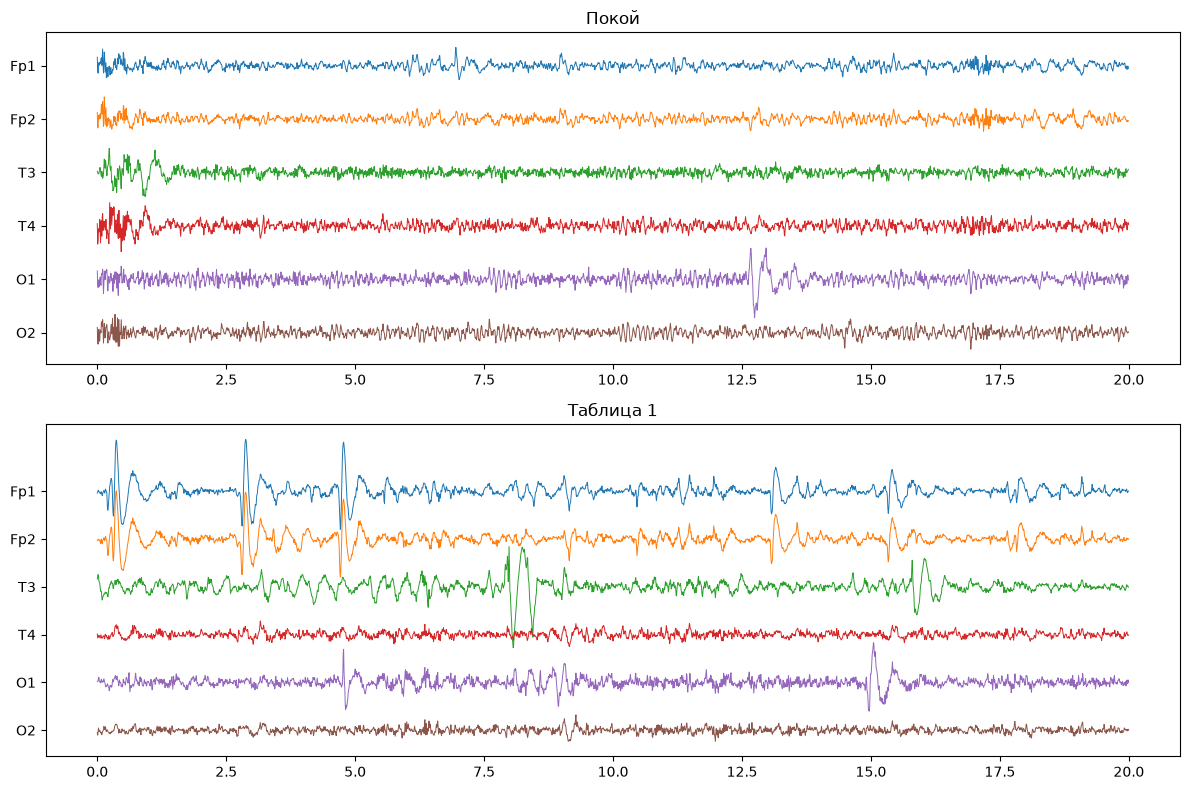

In [26]:
# глазами: один испытуемый, покой и одна таблица рядом
subj_dir = DATA_DIR / "ПТСР" / "34PHG"   # подставьте реальную папку испытуемого
rest_f = ("/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/ПТСР/34PHG/T-П.edf")
task_f = ("/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/ПТСР/34PHG/T-1.edf")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
for ax, path, title in [(axes[0], rest_f, "Покой"), (axes[1], task_f, "Таблица 1")]:
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    n = int(min(20, data.shape[1] / fs) * fs)
    for i, ch in enumerate(CHANNELS):
        ax.plot(np.arange(n) / fs, data[i, :n] - i * 200, lw=0.7)
    ax.set_yticks([-i * 200 for i in range(6)], CHANNELS)
    ax.set_title(title)
plt.tight_layout()
plt.show()


In [27]:
dur_rows = []
for _, row in df.iterrows():
    f = DATA_DIR / row["group"] / row["subject"] / row["file"]
    dur_rows.append(dict(group=row["group"], subject=row["subject"], file=row["file"],
                          kind=row["kind"], duration_s=row["duration_s"]))
dur_df = pd.DataFrame(dur_rows)

print("--- Подозрительно короткие/длинные записи покоя ---")
rest = dur_df[dur_df["kind"] == "rest"]
print(rest[(rest["duration_s"] < 45) | (rest["duration_s"] > 90)].sort_values("duration_s"))

print("\n--- Подозрительно короткие таблицы (<5с) ---")
task = dur_df[dur_df["kind"] != "rest"]
print(task[task["duration_s"] < 5].sort_values("duration_s"))


--- Подозрительно короткие/длинные записи покоя ---
             group subject     file  kind  duration_s
743  Соматоформные   LPQW8  T-П.edf  rest        32.0
533           ПТСР    VCVB  T-П.edf  rest        35.0
539           ПТСР    WSDF  T-П.edf  rest        35.0
431           ПТСР    FGTG  T-П.edf  rest        37.0
449           ПТСР    IUJM  T-П.edf  rest        41.0
437           ПТСР    GHJK  T-П.edf  rest        41.0
671  Соматоформные   GHRD3  T-П.edf  rest        44.0
791  Соматоформные   PTMJ6  T-П.edf  rest        98.0
851  Соматоформные   RZFM9  T-П.edf  rest       105.0
911  Соматоформные   VGYN1  T-П.edf  rest       105.0
959  Соматоформные   YLKT9  T-П.edf  rest       121.0

--- Подозрительно короткие таблицы (<5с) ---
             group subject     file    kind  duration_s
561  Соматоформные   ASDF9  T-4.edf  task_4         1.0


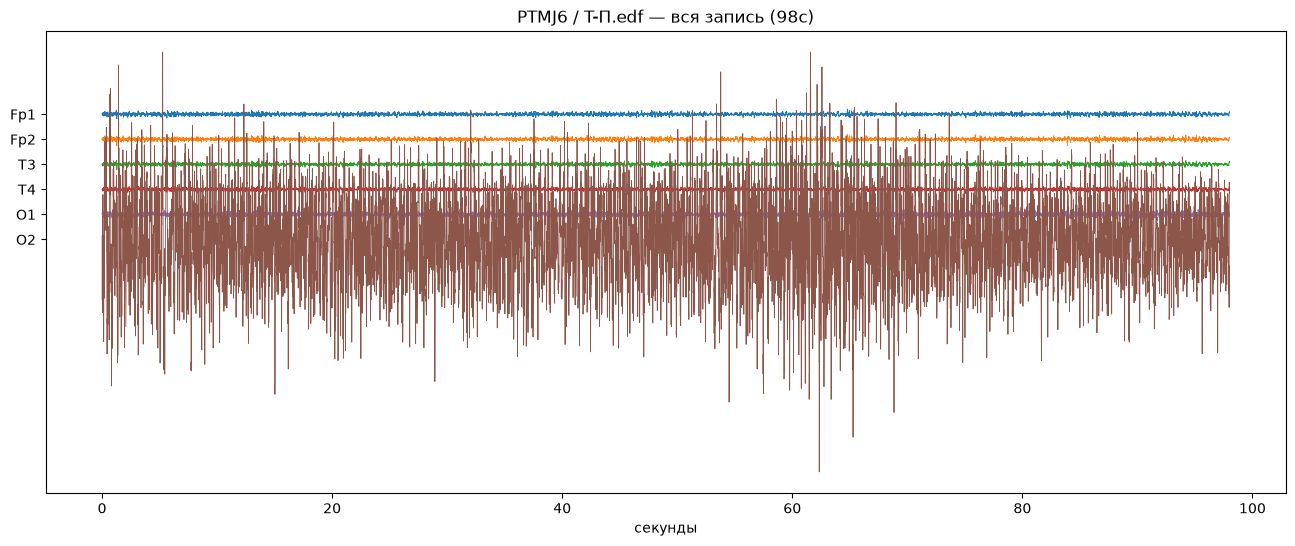

In [28]:
long_rest = rest[rest["duration_s"] > 90].iloc[0]  # берём один из длинных для примера
f = DATA_DIR / long_rest["group"] / long_rest["subject"] / long_rest["file"]

raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
raw.pick(CHANNELS)
data = raw.get_data() * 1e6
fs = raw.info["sfreq"]

plt.figure(figsize=(16, 6))
for i, ch in enumerate(CHANNELS):
    plt.plot(np.arange(data.shape[1]) / fs, data[i] - i * 300, lw=0.6)
plt.yticks([-i * 300 for i in range(6)], CHANNELS)
plt.xlabel("секунды")
plt.title(f"{long_rest['subject']} / {long_rest['file']} — вся запись ({long_rest['duration_s']:.0f}с)")
plt.show()


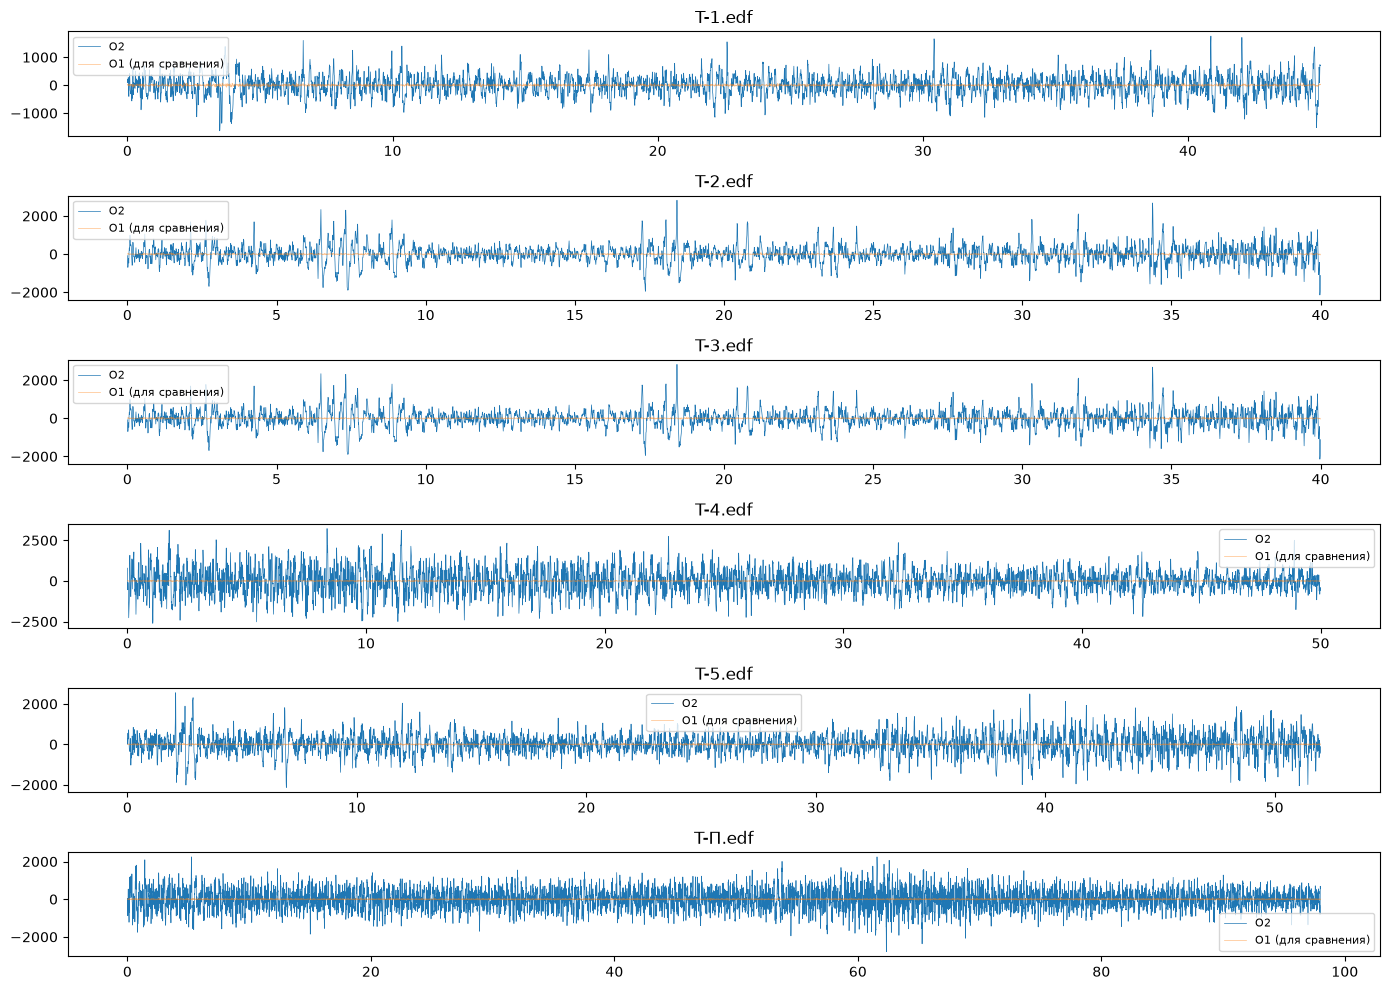

In [29]:
subj_dir = DATA_DIR / long_rest["group"] / long_rest["subject"]

fig, axes = plt.subplots(6, 1, figsize=(14, 10), sharex=False)
for ax, f in zip(axes, sorted(subj_dir.glob("*.edf"))):
    raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    o2_idx = CHANNELS.index("O2")
    ax.plot(np.arange(data.shape[1]) / fs, data[o2_idx], lw=0.5, label="O2")
    ax.plot(np.arange(data.shape[1]) / fs, data[CHANNELS.index("O1")], lw=0.5, alpha=0.5, label="O1 (для сравнения)")
    ax.set_title(f.name)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


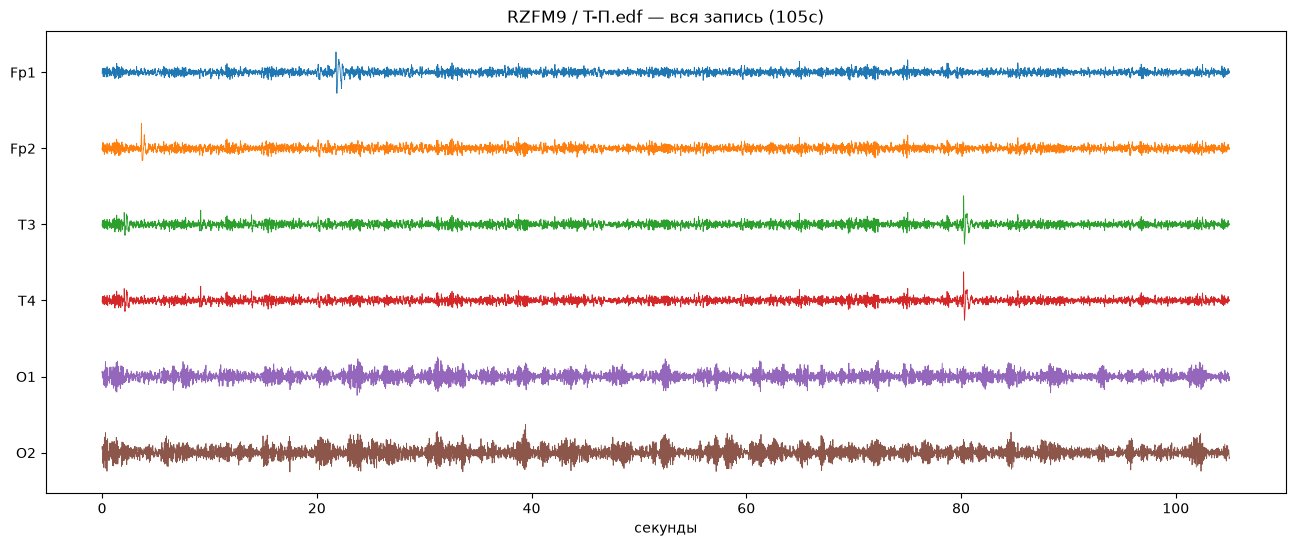

In [30]:
long_rest = rest[rest["duration_s"] > 100].iloc[0]  # берём один из длинных для примера
f = DATA_DIR / long_rest["group"] / long_rest["subject"] / long_rest["file"]

raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
raw.pick(CHANNELS)
data = raw.get_data() * 1e6
fs = raw.info["sfreq"]

plt.figure(figsize=(16, 6))
for i, ch in enumerate(CHANNELS):
    plt.plot(np.arange(data.shape[1]) / fs, data[i] - i * 300, lw=0.6)
plt.yticks([-i * 300 for i in range(6)], CHANNELS)
plt.xlabel("секунды")
plt.title(f"{long_rest['subject']} / {long_rest['file']} — вся запись ({long_rest['duration_s']:.0f}с)")
plt.show()


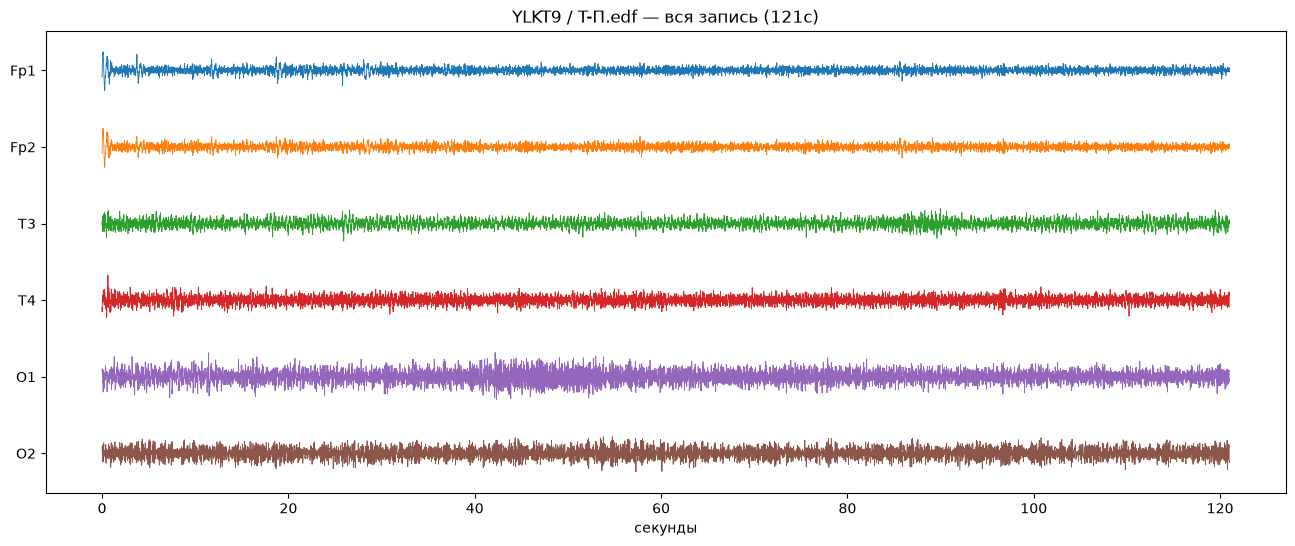

In [31]:
long_rest = rest[rest["duration_s"] > 110].iloc[0]  # берём один из длинных для примера
f = DATA_DIR / long_rest["group"] / long_rest["subject"] / long_rest["file"]

raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
raw.pick(CHANNELS)
data = raw.get_data() * 1e6
fs = raw.info["sfreq"]

plt.figure(figsize=(16, 6))
for i, ch in enumerate(CHANNELS):
    plt.plot(np.arange(data.shape[1]) / fs, data[i] - i * 300, lw=0.6)
plt.yticks([-i * 300 for i in range(6)], CHANNELS)
plt.xlabel("секунды")
plt.title(f"{long_rest['subject']} / {long_rest['file']} — вся запись ({long_rest['duration_s']:.0f}с)")
plt.show()


In [32]:
# для каждого испытуемого: не выделяется ли один канал на фоне остальных пяти (по покою)
outlier_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        rest_files = [f for f in subj_dir.glob("*.edf")]  # возьмём покой, если найдём по имени
        rest_f = next((f for f in rest_files if classify_file(f.stem) == "rest"), None)
        if rest_f is None:
            continue
        try:
            raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
            raw.pick(CHANNELS)
            data = raw.get_data() * 1e6
            rms = data.std(axis=1)  # RMS по каждому из 6 каналов
            med = np.median(rms)
            ratio = rms.max() / med  # во сколько раз самый "громкий" канал выделяется на фоне медианы
            bad_ch = CHANNELS[rms.argmax()]
            outlier_rows.append(dict(group=group_dir.name, subject=subj_dir.name,
                                      ratio=ratio, bad_channel=bad_ch))
        except Exception:
            pass

odf = pd.DataFrame(outlier_rows).sort_values("ratio", ascending=False)
print(odf.head(15))


/tmp/ipykernel_18354/699573322.py:14: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
/tmp/ipykernel_18354/699573322.py:14: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
/tmp/ipykernel_18354/699573322.py:14: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)


             group   subject       ratio bad_channel
95   Соматоформные     BIOM7  269.884935          T3
100  Соматоформные     DGHT1  147.013552          O1
135  Соматоформные     QWER4  136.097565          T3
92   Соматоформные     ABXZ5   63.644754          T3
125  Соматоформные     MNBV6   45.566199          T4
154  Соматоформные     WXYZ1   44.373736          T3
131  Соматоформные     PTMJ6   40.963551          O2
111  Соматоформные     GHRD3   32.870451          T3
164  Соматоформные     ZWAX5   30.067869          T3
7            Норма  КС017_51   27.939353          T3
115  Соматоформные     KJFS5   27.290890          T4
106  Соматоформные     EMFA2   21.072700          T4
122  Соматоформные     LMNO7   19.402820          T3
101  Соматоформные     DIKL0   18.714854          T4
129  Соматоформные     PMML3   15.153005          T4


/tmp/ipykernel_18354/699573322.py:14: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
/tmp/ipykernel_18354/699573322.py:14: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
/tmp/ipykernel_18354/699573322.py:14: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)


вот у этих тоже беда по каналам, надо посмотреть и подумать, че делать с ними

In [33]:
df = df[df["subject"] != "PTMJ6"].reset_index(drop=True)


In [34]:
from scipy import signal
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}

def clean_epochs(data, fs, win_s=2.0, z_thresh=4.0):
    """Режем запись на окна по 2с (перекрытие 50%), выбрасываем окна-выбросы по RMS."""
    L = int(win_s * fs)
    starts = np.arange(0, data.shape[1] - L + 1, L // 2)
    if len(starts) < 3:
        return None
    epochs = np.stack([data[:, s:s+L] for s in starts])  # [n_окон, каналы, L]
    rms = epochs.std(axis=2)
    med = np.median(rms, axis=0)
    mad = np.median(np.abs(rms - med), axis=0) * 1.4826 + 1e-12
    zmax = ((rms - med) / mad).max(axis=1)
    keep = zmax <= z_thresh
    if keep.sum() < 3:                       # если отбраковали почти всё — берём хотя бы 3 лучших окна
        keep = zmax <= np.sort(zmax)[min(2, len(zmax) - 1)]
    return epochs[keep]

def relative_band_power(epochs, fs, bands=BANDS):
    """epochs: [n_окон, каналы, L]. Возвращает {диапазон: массив по каналам}."""
    f, p = signal.welch(epochs, fs=fs, nperseg=epochs.shape[-1], axis=-1)
    p = np.median(p, axis=0)  # медиана по окнам — устойчиво к тому, что не отбраковалось
    total = p[:, (f >= 1) & (f <= 40)].sum(axis=1, keepdims=True)
    return {name: (p[:, (f >= lo) & (f < hi)].sum(axis=1) / total[:, 0])
            for name, (lo, hi) in bands.items()}


In [35]:
raw = mne.io.read_raw_edf("/home/karpushenkova/atacheskaya-panika/data/neurodiagnostics-train/Норма/КС011_25/T-П.edf", preload=True, verbose=False)
raw.pick(CHANNELS)
data = raw.get_data() * 1e6
fs = raw.info["sfreq"]

epochs = clean_epochs(data, fs)
n_total = (data.shape[1] - int(2*fs)) // (int(2*fs)//2) + 1
print(f"Окон: {n_total} всего, {epochs.shape[0]} осталось после отбраковки")

rp = relative_band_power(epochs, fs)
for band, vals in rp.items():
    print(f"{band:6s}", dict(zip(CHANNELS, vals.round(3))))

total_check = sum(v for v in rp.values())
print("Сумма долей по каналам (должна быть ≈1):", total_check.round(3))

Окон: 61 всего, 37 осталось после отбраковки
delta  {'Fp1': np.float64(0.352), 'Fp2': np.float64(0.386), 'T3': np.float64(0.38), 'T4': np.float64(0.283), 'O1': np.float64(0.344), 'O2': np.float64(0.251)}
theta  {'Fp1': np.float64(0.149), 'Fp2': np.float64(0.173), 'T3': np.float64(0.136), 'T4': np.float64(0.183), 'O1': np.float64(0.114), 'O2': np.float64(0.188)}
alpha  {'Fp1': np.float64(0.284), 'Fp2': np.float64(0.246), 'T3': np.float64(0.152), 'T4': np.float64(0.28), 'O1': np.float64(0.319), 'O2': np.float64(0.353)}
beta   {'Fp1': np.float64(0.149), 'Fp2': np.float64(0.14), 'T3': np.float64(0.221), 'T4': np.float64(0.19), 'O1': np.float64(0.178), 'O2': np.float64(0.184)}
gamma  {'Fp1': np.float64(0.063), 'Fp2': np.float64(0.054), 'T3': np.float64(0.103), 'T4': np.float64(0.062), 'O1': np.float64(0.044), 'O2': np.float64(0.023)}
Сумма долей по каналам (должна быть ≈1): [0.997 0.998 0.992 0.998 0.999 0.999]


В литобзоре самым воспроизводимым маркером ПТСР была именно межполушарная асимметрия альфы (право/лево). Считаем как разницу логарифмов мощности между правым и левым каналом одной пары (Fp1/Fp2, T3/T4, O1/O2), а не просто разницу или отношение — это стандартный в литературе способ, и он же продолжает нашу тему устойчивости к масштабу: разница логарифмов = логарифм отношения, то есть тоже не зависит от общего масштаба записи.

In [36]:
ASYM_PAIRS = {"Fp": ("Fp1", "Fp2"), "T": ("T3", "T4"), "O": ("O1", "O2")}
ci = {ch: i for i, ch in enumerate(CHANNELS)}

def asymmetry_features(rp, bands=("theta", "alpha", "beta")):
    """log(правый канал) - log(левый канал), по каждой паре и диапазону.
    Положительное значение = справа активность выше, чем слева."""
    out = {}
    for band in bands:
        logp = np.log10(rp[band] + 1e-12)
        for name, (left, right) in ASYM_PAIRS.items():
            out[f"asym_{band}_{name}"] = logp[ci[right]] - logp[ci[left]]
    return out

asym = asymmetry_features(rp)
for k, v in asym.items():
    print(k, round(v, 3))


asym_theta_Fp 0.065
asym_theta_T 0.129
asym_theta_O 0.218
asym_alpha_Fp -0.064
asym_alpha_T 0.265
asym_alpha_O 0.045
asym_beta_Fp -0.028
asym_beta_T -0.064
asym_beta_O 0.014


In [37]:
def aperiodic_and_peak(epochs, fs, fit_range=(2, 30), alpha_range=(7, 13.5), exclude_alpha=(7, 14)):
    f, p = signal.welch(epochs, fs=fs, nperseg=epochs.shape[-1], axis=-1)
    p = np.median(p, axis=0)                          # [каналы, частоты]
    total = p[:, (f >= 1) & (f <= 40)].sum(axis=1, keepdims=True)
    Pn = p / total                                     # та же относительная нормировка, что и раньше

    # подгоняем прямую вне альфа-диапазона (чтобы пик её не искажал)
    fit_mask = (f >= fit_range[0]) & (f <= fit_range[1]) & ~((f >= exclude_alpha[0]) & (f <= exclude_alpha[1]))
    lf = np.log10(f[fit_mask])
    ly = np.log10(Pn[:, fit_mask] + 1e-15)
    slope, icpt = np.polyfit(lf, ly.T, 1)               # своя прямая на каждый канал

    # остаток = реальная мощность минус то, что предсказывает прямая, внутри альфа-диапазона
    am = (f >= alpha_range[0]) & (f <= alpha_range[1])
    predicted = slope[:, None] * np.log10(f[am]) + icpt[:, None]
    resid = np.log10(Pn[:, am] + 1e-15) - predicted

    out = {}
    for i, ch in enumerate(CHANNELS):
        out[f"{ch}__exponent"] = -slope[i]              # больше = круче спад фона
        out[f"{ch}__alpha_peak_height"] = resid[i].max()  # насколько пик выступает над фоном
        out[f"{ch}__alpha_peak_freq"] = f[am][resid[i].argmax()]
    return out

ap = aperiodic_and_peak(epochs, fs)   # epochs, fs уже в памяти с прошлого шага
for k, v in ap.items():
    print(k, round(v, 3))


Fp1__exponent 1.266
Fp1__alpha_peak_height 0.928
Fp1__alpha_peak_freq 12.0
Fp2__exponent 1.419
Fp2__alpha_peak_height 0.765
Fp2__alpha_peak_freq 12.0
T3__exponent 1.05
T3__alpha_peak_height 0.469
T3__alpha_peak_freq 12.0
T4__exponent 1.221
T4__alpha_peak_height 0.708
T4__alpha_peak_freq 12.5
O1__exponent 1.275
O1__alpha_peak_height 1.019
O1__alpha_peak_freq 11.5
O2__exponent 1.384
O2__alpha_peak_height 1.153
O2__alpha_peak_freq 12.0


клод предлагает вот такую вещь, но источник у него 2004 года, тут надо подумать

синхронность между удалёнными областями мозга может отражать, насколько активно они "общаются" друг с другом.

Проблема в лоб посчитанной синхронности. Все наши электроды на одной голове, близко друг к другу, с общим референсом на ухе. Электрический сигнал от одного источника физически "растекается" по тканям и попадает сразу на несколько соседних электродов — они окажутся "синхронны" просто потому, что мерят почти одно и то же место, а не потому что два разных участка мозга реально взаимодействуют. Обычная когерентность на такую ложную синхронность купится.

Хитрость — берём только мнимую часть. Растекание сигнала (и общий референс) происходит мгновенно, без задержки. А если два разных участка мозга реально "общаются" — сигнал должен пройти по нейронным путям, это всегда занимает какое-то ненулевое время, то есть между каналами будет фазовый сдвиг. Когерентность — комплексное число; его вещественная часть ловит "синхронно без задержки" (то есть в основном артефакт растекания), а мнимая часть — именно "синхронно, но со сдвигом по фазе", то, что нельзя объяснить банальным растеканием. Поэтому берём только её (метод Nolte et al. 2004, был в нашем литобзоре).

In [38]:
CONN_PAIRS = [("Fp1", "Fp2"), ("T3", "T4"), ("O1", "O2"),
              ("Fp1", "T3"), ("T3", "O1"), ("Fp2", "T4"), ("T4", "O2")]
CONN_BANDS = ("theta", "alpha", "beta")

def imaginary_coherence(epochs, fs, pairs=CONN_PAIRS, bands=CONN_BANDS):
    """epochs: [n_окон, каналы, L]. Мнимая когерентность между парами каналов по диапазонам."""
    X = np.fft.rfft(epochs * np.hanning(epochs.shape[-1]), axis=-1)  # комплексный спектр каждого окна
    f = np.fft.rfftfreq(epochs.shape[-1], 1 / fs)

    Sxx = np.mean(np.abs(X) ** 2, axis=0)                # автоспектр, усреднённый по окнам
    ci = {ch: i for i, ch in enumerate(CHANNELS)}

    out = {}
    for a, b in pairs:
        i, j = ci[a], ci[b]
        Sxy = np.mean(X[:, i] * np.conj(X[:, j]), axis=0)  # кросс-спектр пары, усреднённый по окнам
        icoh = np.abs(Sxy.imag) / np.sqrt(Sxx[i] * Sxx[j] + 1e-30)
        for band in bands:
            lo, hi = BANDS[band]
            mask = (f >= lo) & (f < hi)
            out[f"icoh_{a}-{b}_{band}"] = float(icoh[mask].mean())
    return out

conn = imaginary_coherence(epochs, fs)   # epochs, fs всё ещё в памяти
for k, v in conn.items():
    print(k, round(v, 3))


icoh_Fp1-Fp2_theta 0.071
icoh_Fp1-Fp2_alpha 0.031
icoh_Fp1-Fp2_beta 0.065
icoh_T3-T4_theta 0.084
icoh_T3-T4_alpha 0.073
icoh_T3-T4_beta 0.131
icoh_O1-O2_theta 0.14
icoh_O1-O2_alpha 0.198
icoh_O1-O2_beta 0.112
icoh_Fp1-T3_theta 0.104
icoh_Fp1-T3_alpha 0.081
icoh_Fp1-T3_beta 0.105
icoh_T3-O1_theta 0.066
icoh_T3-O1_alpha 0.113
icoh_T3-O1_beta 0.077
icoh_Fp2-T4_theta 0.103
icoh_Fp2-T4_alpha 0.074
icoh_Fp2-T4_beta 0.097
icoh_T4-O2_theta 0.105
icoh_T4-O2_alpha 0.148
icoh_T4-O2_beta 0.086


In [39]:
def compute_file_features(path):
    """Все признаки одного файла (относительная мощность + асимметрия + апериодика/пик + связность)."""
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    duration_s = data.shape[1] / fs

    epochs = clean_epochs(data, fs)
    if epochs is None:
        return None, duration_s

    rp = relative_band_power(epochs, fs)
    feats = {f"{ch}__rel_{band}": float(vals[i]) for band, vals in rp.items() for i, ch in enumerate(CHANNELS)}
    feats.update(asymmetry_features(rp))
    feats.update(aperiodic_and_peak(epochs, fs))
    feats.update(imaginary_coherence(epochs, fs))
    return feats, duration_s


In [40]:
EXCLUDE_SUBJECTS = {"XCFU5", "PTMJ6"}  # код испытуемого с шумным O2

def subject_row(subj_dir, group, age):
    if subj_dir.name in EXCLUDE_SUBJECTS:
        return None

    files = list(subj_dir.glob("*.edf"))
    rest_f = next((f for f in files if classify_file(f.stem) == "rest"), None)
    task_files = [f for f in files if classify_file(f.stem).startswith("task")]

    row = {"subject_id": f"{group}/{subj_dir.name}", "group": group, "age": age}

    rest_feats = None
    if rest_f is not None:
        try:
            rest_feats, _ = compute_file_features(rest_f)
        except Exception as e:
            print(f"[!] {rest_f}: {e}")
    if rest_feats:
        row.update({f"rest__{k}": v for k, v in rest_feats.items()})

    task_list, durations = [], []
    for f in task_files:
        try:
            feats, dur = compute_file_features(f)
            durations.append(dur)
            if feats:
                task_list.append(feats)
        except Exception as e:
            print(f"[!] {f}: {e}")

    if task_list:
        for k in task_list[0].keys():
            med = float(np.nanmedian([t.get(k, np.nan) for t in task_list]))
            row[f"task__{k}"] = med
            if rest_feats and k in rest_feats:
                row[f"react__{k}"] = med - rest_feats[k]   # реактивность: таблица минус покой

    if durations:
        row["beh__log_mean_dur"] = float(np.mean(np.log(np.maximum(durations, 1.0))))

    return row


In [41]:
def get_age(group_name, subj_name):
    """Возраст закодирован в имени папки только для группы 'Норма'."""
    if not group_name.lower().startswith("норм"):
        return None
    m = re.search(r"_(\d+)$", subj_name)
    return int(m.group(1)) if m else None

def build_dataset(data_dir, subject_limit=None):
    """subject_limit — сколько испытуемых брать из каждой группы (None = все)."""
    rows = []
    for group_dir in sorted(Path(data_dir).iterdir()):
        if not group_dir.is_dir():
            continue
        subj_dirs = [d for d in sorted(group_dir.iterdir()) if d.is_dir()]
        if subject_limit:
            subj_dirs = subj_dirs[:subject_limit]
        for subj_dir in subj_dirs:
            age = get_age(group_dir.name, subj_dir.name)
            row = subject_row(subj_dir, group_dir.name, age)
            if row:
                rows.append(row)
    return pd.DataFrame(rows)

In [42]:
test_df = build_dataset(DATA_DIR, subject_limit=3)
print(test_df.shape)
test_df.head()

(9, 238)


,subject_id,group,age,rest__Fp1__rel_delta,rest__Fp2__rel_delta,rest__T3__rel_delta,rest__T4__rel_delta,rest__O1__rel_delta,rest__O2__rel_delta,rest__Fp1__rel_theta,...,react__icoh_Fp2-T4_alpha,task__icoh_Fp2-T4_beta,react__icoh_Fp2-T4_beta,task__icoh_T4-O2_theta,react__icoh_T4-O2_theta,task__icoh_T4-O2_alpha,react__icoh_T4-O2_alpha,task__icoh_T4-O2_beta,react__icoh_T4-O2_beta,beh__log_mean_dur
0,Норма/КС010_19,Норма,19.0,0.688836,0.646523,0.282649,0.344866,0.091697,0.094179,0.156386,...,-0.062179,0.080030,-0.001711,0.086772,0.015936,0.094778,-0.164282,0.094801,0.013981,3.849576
1,Норма/КС011_25,Норма,25.0,0.351847,0.385831,0.380439,0.282867,0.344471,0.251104,0.148673,...,0.006665,0.103753,0.007155,0.082446,-0.022307,0.092667,-0.054852,0.081869,-0.004328,3.947967
2,Норма/КС012_58,Норма,58.0,0.284906,0.255489,0.124382,0.196379,0.059862,0.054349,0.179785,...,0.033296,0.089200,0.011336,0.127574,0.083513,0.077257,-0.018619,0.084198,-0.016323,3.907977
3,ПТСР/34PHG,ПТСР,NaN,0.222299,0.199847,0.157288,0.119918,0.051722,0.081458,0.159067,...,-0.091113,0.086540,-0.019552,0.057529,-0.040728,0.096462,-0.116718,0.083044,0.008047,4.064413
4,ПТСР/BGVF,ПТСР,NaN,0.183675,0.154513,0.087908,0.113348,0.161238,0.227172,0.214981,...,0.017788,0.098483,0.003331,0.115301,0.068740,0.115801,0.051351,0.110461,0.002905,3.549975


In [43]:
test_df.shape

(9, 238)

In [44]:
test_df

,subject_id,group,age,rest__Fp1__rel_delta,rest__Fp2__rel_delta,rest__T3__rel_delta,rest__T4__rel_delta,rest__O1__rel_delta,rest__O2__rel_delta,rest__Fp1__rel_theta,...,react__icoh_Fp2-T4_alpha,task__icoh_Fp2-T4_beta,react__icoh_Fp2-T4_beta,task__icoh_T4-O2_theta,react__icoh_T4-O2_theta,task__icoh_T4-O2_alpha,react__icoh_T4-O2_alpha,task__icoh_T4-O2_beta,react__icoh_T4-O2_beta,beh__log_mean_dur
0,Норма/КС010_19,Норма,19.0,0.688836,0.646523,0.282649,0.344866,0.091697,0.094179,0.156386,...,-0.062179,0.080030,-0.001711,0.086772,0.015936,0.094778,-0.164282,0.094801,0.013981,3.849576
1,Норма/КС011_25,Норма,25.0,0.351847,0.385831,0.380439,0.282867,0.344471,0.251104,0.148673,...,0.006665,0.103753,0.007155,0.082446,-0.022307,0.092667,-0.054852,0.081869,-0.004328,3.947967
2,Норма/КС012_58,Норма,58.0,0.284906,0.255489,0.124382,0.196379,0.059862,0.054349,0.179785,...,0.033296,0.089200,0.011336,0.127574,0.083513,0.077257,-0.018619,0.084198,-0.016323,3.907977
3,ПТСР/34PHG,ПТСР,NaN,0.222299,0.199847,0.157288,0.119918,0.051722,0.081458,0.159067,...,-0.091113,0.086540,-0.019552,0.057529,-0.040728,0.096462,-0.116718,0.083044,0.008047,4.064413
4,ПТСР/BGVF,ПТСР,NaN,0.183675,0.154513,0.087908,0.113348,0.161238,0.227172,0.214981,...,0.017788,0.098483,0.003331,0.115301,0.068740,0.115801,0.051351,0.110461,0.002905,3.549975
5,ПТСР/DFGH,ПТСР,NaN,0.721953,0.706968,0.246600,0.250761,0.071349,0.090673,0.167800,...,-0.024730,0.074363,-0.000046,0.073020,-0.022073,0.094776,-0.050917,0.100576,0.025712,3.400975
6,Соматоформные/ABXZ5,Соматоформные,NaN,0.384664,0.450374,0.162197,0.218493,0.101671,0.062831,0.181231,...,0.006005,0.129463,0.067621,0.121270,0.060408,0.117033,0.059707,0.106213,0.033098,3.460783
7,Соматоформные/ASDF9,Соматоформные,NaN,0.430941,0.431108,0.364922,0.347789,0.365860,0.329864,0.261565,...,0.045097,0.098243,0.059174,0.061561,-0.009721,0.059673,-0.039805,0.070889,0.029263,3.082105
8,Соматоформные/BCRX1,Соматоформные,NaN,0.170674,0.186439,0.250480,0.206318,0.169136,0.217384,0.176536,...,-0.006541,0.074637,0.007268,0.087963,-0.027126,0.058258,-0.008372,0.050864,-0.031021,3.992255


In [45]:
def build_dataset(data_dir, subject_limit=None):
    rows = []
    n_done, n_failed = 0, 0
    for group_dir in sorted(Path(data_dir).iterdir()):
        if not group_dir.is_dir():
            continue
        subj_dirs = [d for d in sorted(group_dir.iterdir()) if d.is_dir()]
        if subject_limit:
            subj_dirs = subj_dirs[:subject_limit]
        for subj_dir in subj_dirs:
            age = get_age(group_dir.name, subj_dir.name)
            try:
                row = subject_row(subj_dir, group_dir.name, age)
                if row:
                    rows.append(row)
                n_done += 1
            except Exception as e:
                print(f"[FAIL] {group_dir.name}/{subj_dir.name}: {e}")
                n_failed += 1
            if (n_done + n_failed) % 10 == 0:
                print(f"...обработано {n_done + n_failed}")
    print(f"Готово: {n_done} успешно, {n_failed} с ошибкой")
    return pd.DataFrame(rows)


In [46]:
feat_df = build_dataset(DATA_DIR)
print(feat_df.shape)
feat_df.to_csv("subject_features.csv", index=False)


...обработано 10
...обработано 20
...обработано 30
...обработано 40
...обработано 50
...обработано 60
...обработано 70


/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


...обработано 80


/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


...обработано 90
...обработано 100


...

...обработано 110


/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


...обработано 120
...обработано 130
...обработано 140


/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.

...обработано 150
...обработано 160
Готово: 166 успешно, 0 с ошибкой
(164, 238)


In [47]:
print("Испытуемых без rest__ (нет покоя):", feat_df.filter(like="rest__").isna().all(axis=1).sum())
print("Испытуемых без task__ (нет ни одной таблицы):", feat_df.filter(like="task__").isna().all(axis=1).sum())
print()
print("Топ-10 столбцов с наибольшим числом пропусков:")
print(feat_df.isna().sum().sort_values(ascending=False).head(10))

Испытуемых без rest__ (нет покоя): 0
Испытуемых без task__ (нет ни одной таблицы): 0

Топ-10 столбцов с наибольшим числом пропусков:
age                     97
subject_id               0
group                    0
rest__Fp1__rel_delta     0
rest__Fp2__rel_delta     0
rest__T3__rel_delta      0
rest__T4__rel_delta      0
rest__O1__rel_delta      0
rest__O2__rel_delta      0
rest__Fp1__rel_theta     0
dtype: int64


In [48]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import roc_auc_score

y = feat_df["group"].str.lower().str.startswith("птср").astype(int)
print(y.value_counts())   # сколько ПТСР против остальных

meta_cols = ["subject_id", "group", "age"]
feature_cols = [c for c in feat_df.columns if c not in meta_cols]
X = feat_df[feature_cols].values

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(f_classif, k=25)),
    ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
])

oof_proba = cross_val_predict(pipe, X, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
auc = roc_auc_score(y, oof_proba)
print(f"AUC (честный LOSO, ПТСР против нормы+соматоформных): {auc:.3f}")


group
0    139
1     25
Name: count, dtype: int64
AUC (честный LOSO, ПТСР против нормы+соматоформных): 0.885


In [49]:
from scipy import stats

groups = feat_df["group"].str.lower()
is_ptsd = groups.str.startswith("птср")
is_norm = groups.str.startswith("норм")
is_somato = groups.str.startswith("сомат")

def bootstrap_auc(y, s, n=2000, seed=0):
    y, s = np.asarray(y), np.asarray(s)
    rng = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    bs = [roc_auc_score(y[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])],
                          s[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])])
          for _ in range(n)]
    return roc_auc_score(y, s), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

m = is_ptsd | is_norm
auc, lo, hi = bootstrap_auc(y[m], oof_proba[m])
print(f"AUC ПТСР vs Норма: {auc:.3f}  95% ДИ [{lo:.3f}, {hi:.3f}]")

fpr_norm = (oof_proba[is_norm] >= 0.5).mean()
fpr_somato = (oof_proba[is_somato] >= 0.5).mean()
print(f"Ложные ПТСР на норме при пороге 0.5: {fpr_norm:.1%}")
print(f"Ложные ПТСР на соматоформных при пороге 0.5: {fpr_somato:.1%}")


AUC ПТСР vs Норма: 0.920  95% ДИ [0.855, 0.971]
Ложные ПТСР на норме при пороге 0.5: 10.4%
Ложные ПТСР на соматоформных при пороге 0.5: 15.3%


In [50]:
from sklearn.linear_model import Ridge

# --- 1. Предсказываем возраст по тем же признакам внутри "Нормы" (п.2.2 ТЗ, обязательно) ---
norm_mask = is_norm.values & feat_df["age"].notna().values
X_norm = feat_df.loc[norm_mask, feature_cols].values
age_norm = feat_df.loc[norm_mask, "age"].values

age_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("reg", Ridge(alpha=1000.0)),   # сильная регуляризация: признаков много, людей мало
])

pred_age = cross_val_predict(age_pipe, X_norm, age_norm, cv=LeaveOneOut())
rho_age = stats.spearmanr(pred_age, age_norm)
print(f"Предсказание возраста по признакам внутри нормы: r={rho_age.statistic:.3f}, p={rho_age.pvalue:.3f}")
print("(по ТЗ связь должна быть слабой — большое |r| это тревожный сигнал)")

rho_score_age = stats.spearmanr(oof_proba[norm_mask], age_norm)
print(f"Вероятность ПТСР vs возраст внутри нормы: r={rho_score_age.statistic:.3f}, p={rho_score_age.pvalue:.3f}")


Предсказание возраста по признакам внутри нормы: r=0.103, p=0.408
(по ТЗ связь должна быть слабой — большое |r| это тревожный сигнал)
Вероятность ПТСР vs возраст внутри нормы: r=-0.246, p=0.045


In [51]:
# --- 2. Абляция: модель без поведенческих признаков (п.2.2 ТЗ, обязательно) ---
feature_cols_no_beh = [c for c in feature_cols if not c.startswith("beh__")]
X_no_beh = feat_df[feature_cols_no_beh].values

oof_proba_no_beh = cross_val_predict(pipe, X_no_beh, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]

auc_full, _, _ = bootstrap_auc(y[m], oof_proba[m])
auc_no_beh, lo2, hi2 = bootstrap_auc(y[m], oof_proba_no_beh[m])
print(f"AUC ПТСР vs Норма, с поведением:   {auc_full:.3f}")
print(f"AUC ПТСР vs Норма, без поведения:  {auc_no_beh:.3f}  95% ДИ [{lo2:.3f}, {hi2:.3f}]")

rho_beh = stats.spearmanr(oof_proba, feat_df["beh__log_mean_dur"])
print(f"Вероятность ПТСР vs время решения таблиц (вся выборка): r={rho_beh.statistic:.3f}, p={rho_beh.pvalue:.3f}")


AUC ПТСР vs Норма, с поведением:   0.920
AUC ПТСР vs Норма, без поведения:  0.927  95% ДИ [0.866, 0.973]
Вероятность ПТСР vs время решения таблиц (вся выборка): r=0.517, p=0.000


In [52]:
rho_ptsd = stats.spearmanr(oof_proba[is_ptsd], feat_df.loc[is_ptsd, "beh__log_mean_dur"])
rho_norm = stats.spearmanr(oof_proba[is_norm], feat_df.loc[is_norm, "beh__log_mean_dur"])
print(f"Внутри ПТСР: r={rho_ptsd.statistic:.3f}, p={rho_ptsd.pvalue:.3f}")
print(f"Внутри Нормы: r={rho_norm.statistic:.3f}, p={rho_norm.pvalue:.3f}")


Внутри ПТСР: r=0.243, p=0.242
Внутри Нормы: r=0.460, p=0.000


In [53]:
rest_cols = [c for c in feature_cols if c.startswith("rest__")]
X_rest = feat_df[rest_cols].values

oof_proba_rest = cross_val_predict(pipe, X_rest, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]

auc_rest, lo3, hi3 = bootstrap_auc(y[m], oof_proba_rest[m])
print(f"AUC ПТСР vs Норма, только признаки покоя: {auc_rest:.3f}  95% ДИ [{lo3:.3f}, {hi3:.3f}]")

rho_norm_rest = stats.spearmanr(oof_proba_rest[is_norm], feat_df.loc[is_norm, "beh__log_mean_dur"])
print(f"Внутри Нормы (модель только на покое) vs длительность: r={rho_norm_rest.statistic:.3f}, p={rho_norm_rest.pvalue:.3f}")


AUC ПТСР vs Норма, только признаки покоя: 0.864  95% ДИ [0.784, 0.932]
Внутри Нормы (модель только на покое) vs длительность: r=-0.045, p=0.717


In [54]:
rho_norm_no_beh = stats.spearmanr(oof_proba_no_beh[is_norm], feat_df.loc[is_norm, "beh__log_mean_dur"])
print(f"Норма, модель без beh (но с task/react) vs длительность: r={rho_norm_no_beh.statistic:.3f}, p={rho_norm_no_beh.pvalue:.3f}")


Норма, модель без beh (но с task/react) vs длительность: r=0.442, p=0.000


In [55]:
for k in [5, 10, 15, 25, 40, 50, 75, 100, 234]:
    test_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("select", SelectKBest(f_classif, k=min(k, X.shape[1]))),
        ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
    ])
    oof_k = cross_val_predict(test_pipe, X, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    auc_k, lo_k, hi_k = bootstrap_auc(y[m], oof_k[m])
    print(f"k={k:4d}   AUC={auc_k:.3f}   95% ДИ=[{lo_k:.3f}, {hi_k:.3f}]")


k=   5   AUC=0.918   95% ДИ=[0.855, 0.967]
k=  10   AUC=0.918   95% ДИ=[0.856, 0.968]
k=  15   AUC=0.918   95% ДИ=[0.853, 0.970]
k=  25   AUC=0.920   95% ДИ=[0.855, 0.971]
k=  40   AUC=0.937   95% ДИ=[0.887, 0.978]
k=  50   AUC=0.922   95% ДИ=[0.863, 0.970]
k=  75   AUC=0.954   95% ДИ=[0.907, 0.987]
k= 100   AUC=0.949   95% ДИ=[0.899, 0.985]
k= 234   AUC=0.922   95% ДИ=[0.854, 0.973]


In [56]:
norm_ages = feat_df.loc[is_norm, "age"].values
edges = np.quantile(norm_ages[~np.isnan(norm_ages)], [0, 1/3, 2/3, 1])
print("Границы возрастных третей:", edges.round(1))

for k in range(3):
    lo_, hi_ = edges[k], edges[k + 1]
    in_bin = is_norm.values & (feat_df["age"] >= lo_) & ((feat_df["age"] <= hi_) if k == 2 else (feat_df["age"] < hi_))
    n = in_bin.sum()
    mean_p = oof_proba_rest[in_bin].mean()
    fpr = (oof_proba_rest[in_bin] >= 0.5).mean()
    print(f"возраст {lo_:.0f}-{hi_:.0f} лет (n={n}): средняя вероятность={mean_p:.3f}, ложных ПТСР при 0.5={fpr:.1%}")


Границы возрастных третей: [19. 25. 37. 58.]
возраст 19-25 лет (n=19): средняя вероятность=0.380, ложных ПТСР при 0.5=36.8%
возраст 25-37 лет (n=25): средняя вероятность=0.123, ложных ПТСР при 0.5=0.0%
возраст 37-58 лет (n=23): средняя вероятность=0.183, ложных ПТСР при 0.5=8.7%


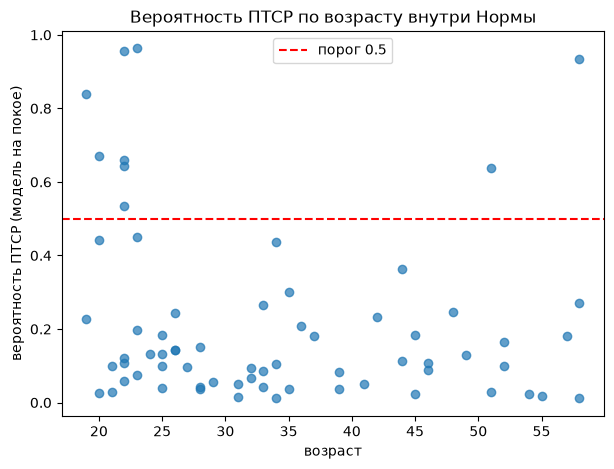

In [57]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.scatter(feat_df.loc[is_norm, "age"], oof_proba_rest[is_norm.values], alpha=0.7)
plt.axhline(0.5, color="red", ls="--", label="порог 0.5")
plt.xlabel("возраст")
plt.ylabel("вероятность ПТСР (модель на покое)")
plt.legend()
plt.title("Вероятность ПТСР по возрасту внутри Нормы")
plt.show()


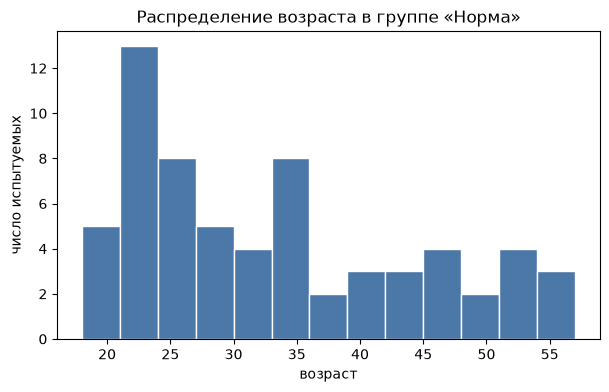

count    67.0
mean     33.9
std      11.9
min      19.0
25%      23.0
50%      32.0
75%      44.0
max      58.0
dtype: float64


In [58]:
# 1. Реально ли молодых больше / распределение возраста скошено?
plt.figure(figsize=(7, 4))
plt.hist(norm_ages, bins=range(18, 60, 3), color="#4c78a8", edgecolor="white")
plt.xlabel("возраст")
plt.ylabel("число испытуемых")
plt.title("Распределение возраста в группе «Норма»")
plt.show()
print(pd.Series(norm_ages).describe().round(1))


In [59]:
# 2. Не хуже ли данные у молодых (короче запись покоя / меньше чистых окон после отбраковки артефактов)?
quality_rows = []
for _, r in feat_df[is_norm].iterrows():
    subj_dir = DATA_DIR / r["group"] / r["subject_id"].split("/")[-1]
    rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
    if rest_f is None:
        continue
    raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    fs = raw.info["sfreq"]
    ep = clean_epochs(data, fs)
    quality_rows.append(dict(age=r["age"], duration_s=data.shape[1] / fs,
                              n_clean_epochs=0 if ep is None else ep.shape[0]))

qdf = pd.DataFrame(quality_rows)
qdf["age_bin"] = pd.cut(qdf["age"], bins=[18, 25, 37, 58], include_lowest=True)
print(qdf.groupby("age_bin")[["duration_s", "n_clean_epochs"]].describe().round(1))


               duration_s                                           \
                    count  mean  std   min   25%   50%   75%   max   
age_bin                                                              
(17.999, 25.0]       23.0  61.2  0.8  60.0  61.0  61.0  61.0  63.0   
(25.0, 37.0]         22.0  61.2  0.7  61.0  61.0  61.0  61.0  64.0   
(37.0, 58.0]         22.0  61.2  0.9  61.0  61.0  61.0  61.0  65.0   

               n_clean_epochs                                           
                        count  mean  std   min   25%   50%   75%   max  
age_bin                                                                 
(17.999, 25.0]           23.0  53.0  8.2  35.0  48.5  57.0  59.0  60.0  
(25.0, 37.0]             22.0  58.0  4.5  39.0  58.0  59.0  60.0  60.0  
(37.0, 58.0]             22.0  57.2  3.8  44.0  56.5  58.5  59.0  60.0  


чистых окон после отбраковки (n_clean_epochs) у молодых заметно ниже в нижней части распределения: 25-й перцентиль — 48.5 у молодых против 58.0 и 56.5 у остальных, минимум — 35 против 39 и 44. Медианы (57 / 59 / 58.5) отличаются не сильно, но у молодых есть заметный "хвост" из людей с более грязными записями.

Проверим точнее — действительно ли именно те 7 молодых, кого модель ошибочно приняла за ПТСР, имеют мало чистых окон (тогда это про качество данных), или это распределено случайно среди всех молодых (тогда дело правда в возрасте, а не в шуме):

In [60]:
young_rows = []
for idx, r in feat_df[is_norm & (feat_df["age"] < 25)].iterrows():
    subj_dir = DATA_DIR / r["group"] / r["subject_id"].split("/")[-1]
    rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
    if rest_f is None:
        continue
    raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
    raw.pick(CHANNELS)
    data = raw.get_data() * 1e6
    ep = clean_epochs(data, raw.info["sfreq"])
    young_rows.append(dict(subject_id=r["subject_id"], age=r["age"],
                            proba=oof_proba_rest[idx],
                            n_clean_epochs=0 if ep is None else ep.shape[0]))

young_df = pd.DataFrame(young_rows).sort_values("proba", ascending=False)
print(young_df[["subject_id", "age", "proba", "n_clean_epochs"]])


        subject_id   age     proba  n_clean_epochs
7   Норма/КС036_23  23.0  0.963104              60
17  Норма/КС146_22  22.0  0.956271              50
9   Норма/КС051_19  19.0  0.839950              57
5   Норма/КС023_20  20.0  0.670149              42
3   Норма/КС016_22  22.0  0.659295              58
4   Норма/КС022_22  22.0  0.642518              49
2   Норма/КС014_22  22.0  0.534445              55
1   Норма/КС013_23  23.0  0.449061              35
6   Норма/КС024_20  20.0  0.443347              44
0   Норма/КС010_19  19.0  0.226074              48
18  Норма/КС148_23  23.0  0.196617              56
11  Норма/КС058_24  24.0  0.130788              59
13  Норма/КС100_22  22.0  0.120795              58
10  Норма/КС056_22  22.0  0.107636              60
8   Норма/КС043_21  21.0  0.098858              55
15  Норма/КС134_23  23.0  0.075151              59
12  Норма/КС080_22  22.0  0.059779              58
14  Норма/КС120_21  21.0  0.029855              60
16  Норма/КС140_20  20.0  0.025

нет корреляции между "грязью" в данных и правильностью предсказания

понять, какие именно признаки различаются между "молодыми ложноположительными" и "молодыми правильно классифицированными", чтобы понять механизм (например, физиологическая незрелость лобной коры до ~25 лет — это отдельная известная вещь в литературе про развитие мозга, не связанная с ПТСР):

In [61]:
young_ids = young_df["subject_id"].values
young_feat = feat_df.set_index("subject_id").loc[young_ids]
fp_mask = young_df["proba"].values >= 0.5

rest_feature_cols = [c for c in feature_cols if c.startswith("rest__")]
diffs = [(c, float(young_feat.loc[fp_mask, c].mean() - young_feat.loc[~fp_mask, c].mean()))
         for c in rest_feature_cols]
diffs_df = pd.DataFrame(diffs, columns=["feature", "diff"])
diffs_df["abs_diff"] = diffs_df["diff"].abs()
print(diffs_df.sort_values("abs_diff", ascending=False).head(15))


                         feature      diff  abs_diff
50     rest__T4__alpha_peak_freq -2.202381  2.202381
47     rest__T3__alpha_peak_freq -1.267857  1.267857
53     rest__O1__alpha_peak_freq  0.750000  0.750000
55   rest__O2__alpha_peak_height  0.712223  0.712223
52   rest__O1__alpha_peak_height  0.602459  0.602459
56     rest__O2__alpha_peak_freq  0.500000  0.500000
54            rest__O2__exponent -0.449367  0.449367
40  rest__Fp1__alpha_peak_height  0.435753  0.435753
43  rest__Fp2__alpha_peak_height  0.401087  0.401087
41    rest__Fp1__alpha_peak_freq  0.380952  0.380952
49   rest__T4__alpha_peak_height  0.359205  0.359205
48            rest__T4__exponent  0.328287  0.328287
45            rest__T3__exponent -0.286270  0.286270
38             rest__asym_beta_O  0.271383  0.271383
51            rest__O1__exponent  0.244570  0.244570


Главные различия — частота и высота альфа-пика (alpha_peak_freq, alpha_peak_height) и наклон спектра (exponent) — ровно те признаки, про которые в литобзоре было написано, что они возраст-чувствительны (Voytek et al. 2015 про наклон 1/f, известная возрастная динамика индивидуальной частоты альфы). То есть модель, судя по всему, действительно частично цепляется за возрастной "хвост" созревания мозга (индивидуальная альфа-частота у молодых ещё продолжает меняться примерно до середины 20-х), а не за что-то бессмысленное.

Важная оговорка: это сравнение всего 7 против 12 человек — статистически ничего не доказывает, это чисто описательная картина, а не подтверждённый результат. Не стоит делать далеко идущих выводов по конкретным числам (типа "T4 alpha_peak_freq отличается на 2.2 Гц") как по надёжному факту.

Практический вывод: эти признаки (альфа-пик, наклон) при этом реально полезны и физиологически интерпретируемы (помните, alpha_peak_height красиво совпал с ожидаемой топографией "сильнее в затылке" — это была хорошая находка). Просто выкинуть их из модели — значит потерять реальный сигнал вместе с шумом. Правильнее — честно описать это ограничение в отчёте: указать, что часть ведущих признаков возраст-чувствительна, что мы это проверили и нашли конкретный механизм (молодая подгруппа нормы), и что это создаёт неопределённость в специфичности на скрытой группе "старение 65+", которую нельзя полностью устранить имеющимися данными.

In [62]:
aperiodic_terms = ["__exponent", "__alpha_peak_height", "__alpha_peak_freq"]
rest_cols_no_ap = [c for c in rest_cols if not any(t in c for t in aperiodic_terms)]
print(f"Убрали {len(rest_cols) - len(rest_cols_no_ap)} признаков из {len(rest_cols)}")

X_rest_no_ap = feat_df[rest_cols_no_ap].values
oof_proba_no_ap = cross_val_predict(pipe, X_rest_no_ap, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]

auc_no_ap, lo4, hi4 = bootstrap_auc(y[m], oof_proba_no_ap[m])
print(f"AUC ПТСР vs Норма, без alpha_peak/exponent: {auc_no_ap:.3f}  95% ДИ [{lo4:.3f}, {hi4:.3f}]")
print(f"(для сравнения, было с ними: 0.864)")
print()

for k in range(3):
    lo_, hi_ = edges[k], edges[k + 1]
    in_bin = is_norm.values & (feat_df["age"] >= lo_) & ((feat_df["age"] <= hi_) if k == 2 else (feat_df["age"] < hi_))
    mean_p = oof_proba_no_ap[in_bin].mean()
    fpr = (oof_proba_no_ap[in_bin] >= 0.5).mean()
    print(f"возраст {lo_:.0f}-{hi_:.0f} лет (n={in_bin.sum()}): средняя вероятность={mean_p:.3f}, ложных ПТСР при 0.5={fpr:.1%}")


Убрали 18 признаков из 78
AUC ПТСР vs Норма, без alpha_peak/exponent: 0.779  95% ДИ [0.681, 0.866]
(для сравнения, было с ними: 0.864)

возраст 19-25 лет (n=19): средняя вероятность=0.447, ложных ПТСР при 0.5=42.1%
возраст 25-37 лет (n=25): средняя вероятность=0.150, ложных ПТСР при 0.5=4.0%
возраст 37-58 лет (n=23): средняя вероятность=0.227, ложных ПТСР при 0.5=17.4%


просело все, то есть убрать не можем признаки, коррелирующие с возрастом, надо подумать, че делать

In [63]:
from sklearn.model_selection import train_test_split
# фильтрация явно, прямо здесь — не полагаемся на старую переменную
rest_cols = [c for c in feat_df.columns if c.startswith("rest__")]
print(f"Признаков покоя: {len(rest_cols)}")

train_idx, test_idx = train_test_split(
    np.arange(len(feat_df)), test_size=0.25, stratify=y, random_state=0
)
train_subjects = feat_df.iloc[train_idx]
test_subjects = feat_df.iloc[test_idx]
print(f"Train: {len(train_subjects)} (ПТСР: {y.values[train_idx].sum()})")
print(f"Test:  {len(test_subjects)}  (ПТСР: {y.values[test_idx].sum()})")

X_train = feat_df.loc[train_subjects.index, rest_cols].values
y_train = y.values[train_idx]

test_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(f_classif, k=25)),
    ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
])
test_pipe.fit(X_train, y_train)
test_model = {"pipe": test_pipe, "feature_names": rest_cols}

# жёсткая проверка — код сам упадёт, если хоть один признак не из покоя
assert all(c.startswith("rest__") for c in test_model["feature_names"]), "найден признак не из покоя!"
print("Проверено: все", len(test_model["feature_names"]), "признаков — только покой")


Признаков покоя: 78
Train: 123 (ПТСР: 19)
Test:  41  (ПТСР: 6)
Проверено: все 78 признаков — только покой


In [64]:
test_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(f_classif, k=25)),
    ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
])
test_pipe.fit(X_train, y_train)
test_model = {"pipe": test_pipe, "feature_names": rest_cols}

In [65]:
# 3. Прогоняем настоящую функцию predict() на каждом испытуемом из test — модель их не видела
results = []
for _, row in test_subjects.iterrows():
    subj_path = DATA_DIR / row["group"] / row["subject_id"].split("/")[-1]
    proba = predict(test_model, subj_path)
    results.append(dict(subject_id=row["subject_id"], group=row["group"],
                         true_label=int(row["group"].lower().startswith("птср")),
                         predicted_proba=proba))

results_df = pd.DataFrame(results)
print(results_df)

auc_test = roc_auc_score(results_df["true_label"], results_df["predicted_proba"])
print(f"\nAUC на тесте: {auc_test:.3f}")

NameError: name 'predict' is not defined

In [66]:
def predict(model, subject_dir):
    """model: {"pipe": ..., "feature_names": [...]}. Возвращает вероятность ПТСР в [0, 1]."""
    subject_dir = Path(subject_dir)
    files = list(subject_dir.glob("*.edf"))
    rest_f = next((f for f in files if classify_file(f.stem) == "rest"), None)
    if rest_f is None:
        return 0.5

    try:
        feats, _ = compute_file_features(rest_f)
    except Exception:
        return 0.5
    if not feats:
        return 0.5

    x = np.array([[feats.get(name.replace("rest__", "", 1), np.nan) for name in model["feature_names"]]])
    proba = model["pipe"].predict_proba(x)[0, 1]
    return float(np.clip(proba, 0.0, 1.0))


def run(model, input_dir, output_csv):
    input_dir = Path(input_dir)
    rows = []
    for subj_dir in sorted(p for p in input_dir.iterdir() if p.is_dir()):
        try:
            p = predict(model, subj_dir)
        except Exception as e:
            print(f"[warn] {subj_dir.name}: {e!r}; выдаю 0.5")
            p = 0.5
        rows.append((subj_dir.name, p))
    with open(output_csv, "w", encoding="utf-8", newline="") as f:
        f.write("subject_id,ptsd_probability\n")
        for s, p in rows:
            f.write(f"{s},{p:.6f}\n")
    print(f"Готово: {output_csv}, строк: {len(rows)}")


rest_cols = [c for c in feat_df.columns if c.startswith("rest__")]
print(f"Признаков покоя: {len(rest_cols)}")

train_idx, test_idx = train_test_split(
    np.arange(len(feat_df)), test_size=0.25, stratify=y, random_state=0
)
train_subjects = feat_df.iloc[train_idx]
test_subjects = feat_df.iloc[test_idx]
print(f"Train: {len(train_subjects)} (ПТСР: {y.values[train_idx].sum()})")
print(f"Test:  {len(test_subjects)}  (ПТСР: {y.values[test_idx].sum()})")

X_train = feat_df.loc[train_subjects.index, rest_cols].values
y_train = y.values[train_idx]

test_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(f_classif, k=25)),
    ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
])
test_pipe.fit(X_train, y_train)
test_model = {"pipe": test_pipe, "feature_names": rest_cols}

assert all(c.startswith("rest__") for c in test_model["feature_names"]), "найден признак не из покоя!"
print("Проверено: все", len(test_model["feature_names"]), "признаков — только покой")

results = []
for _, row in test_subjects.iterrows():
    subj_path = DATA_DIR / row["group"] / row["subject_id"].split("/")[-1]
    proba = predict(test_model, subj_path)
    results.append(dict(subject_id=row["subject_id"], group=row["group"],
                         true_label=int(row["group"].lower().startswith("птср")),
                         predicted_proba=proba))

results_df = pd.DataFrame(results)
print(results_df)

auc_test = roc_auc_score(results_df["true_label"], results_df["predicted_proba"])
print(f"\nAUC на тесте: {auc_test:.3f}")


Признаков покоя: 78
Train: 123 (ПТСР: 19)
Test:  41  (ПТСР: 6)
Проверено: все 78 признаков — только покой


/tmp/ipykernel_18354/2586042022.py:3: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


             subject_id          group  true_label  predicted_proba
0   Соматоформные/BLDY8  Соматоформные           0         0.535299
1        Норма/КС076_28          Норма           0         0.181234
2        Норма/КС066_45          Норма           0         0.348066
3             ПТСР/TIOQ           ПТСР           1         0.229959
4   Соматоформные/FGHJ5  Соматоформные           0         0.265901
5             ПТСР/UJNH           ПТСР           1         0.454770
6   Соматоформные/ABXZ5  Соматоформные           0         0.349153
7   Соматоформные/JWKL7  Соматоформные           0         0.623631
8             ПТСР/HJIK           ПТСР           1         0.678621
9   Соматоформные/TYUI7  Соматоформные           0         0.210239
10  Соматоформные/ZAQH1  Соматоформные           0         0.879128
11  Соматоформные/EHGF2  Соматоформные           0         0.151506
12  Соматоформные/MLNP8  Соматоформные           0         0.149145
13  Соматоформные/EKLP6  Соматоформные          

In [67]:
auc_pt, lo_pt, hi_pt = bootstrap_auc(results_df["true_label"].values, results_df["predicted_proba"].values)
print(f"Этот тест: AUC={auc_pt:.3f}  95% ДИ=[{lo_pt:.3f}, {hi_pt:.3f}]")
print()

for seed in [1, 2, 3, 4]:
    tr_idx, te_idx = train_test_split(np.arange(len(feat_df)), test_size=0.25, stratify=y, random_state=seed)
    tp = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("select", SelectKBest(f_classif, k=25)),
        ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)),
    ])
    tp.fit(feat_df.loc[feat_df.index[tr_idx], rest_cols].values, y.values[tr_idx])
    te_proba = tp.predict_proba(feat_df.loc[feat_df.index[te_idx], rest_cols].values)[:, 1]
    a = roc_auc_score(y.values[te_idx], te_proba)
    print(f"seed={seed}: AUC={a:.3f}  (ПТСР в тесте: {y.values[te_idx].sum()})")


Этот тест: AUC=0.762  95% ДИ=[0.571, 0.919]

seed=1: AUC=0.757  (ПТСР в тесте: 6)
seed=2: AUC=0.905  (ПТСР в тесте: 6)
seed=3: AUC=0.838  (ПТСР в тесте: 6)
seed=4: AUC=0.914  (ПТСР в тесте: 6)


Если усреднить все пять чисел (0.762, 0.757, 0.905, 0.838, 0.914) — получится ≈0.835, гораздо ближе к LOSO-оценке (0.864). А LOSO — это, по сути, то же самое усреднение по разбиениям, только сделанное максимально полно: не 5 случайных кусков, а буквально все 164 возможных варианта "один человек в тесте, остальные в обучении", без потерь данных.

Итог: 0.762 не противоречит 0.864, а подтверждает его 

In [68]:
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score

pred_label = (oof_proba_rest >= 0.5).astype(int)
bal_acc = balanced_accuracy_score(y[m], pred_label[m])
prec = precision_score(y[m], pred_label[m])
rec = recall_score(y[m], pred_label[m])

print(f"Сбалансированная точность: {bal_acc:.3f}")
print(f"Precision (доля реальных ПТСР среди помеченных как ПТСР): {prec:.3f}")
print(f"Recall (доля найденных из реальных ПТСР): {rec:.3f}")


Сбалансированная точность: 0.753
Precision (доля реальных ПТСР среди помеченных как ПТСР): 0.640
Recall (доля найденных из реальных ПТСР): 0.640
